In [1]:
#initialise libraries and packages
import os
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
#initialise variables
variable_type = {
    'metadata_var': ['randhosp_id', 'randpat_id', 'pretrialexp', 'country', 'trialphase', 'phase',
                     'gender', 'weight', 'glucose', 'agecat', 'ageimp', 'age_true', 'UKextra'],
    'randomisation_var': ['age', 'randyear', 'randmonth', 'randhour', 'randmin', 'randdelay', 'livealone_rand', 'indepinadl_rand', 'nobleed_rand', 'infarct', 'antiplat_rand', 'atrialfib_rand', 'sbprand', 'dbprand', 'gcs_eye_rand', 'gcs_motor_rand', 'gcs_verbal_rand', 'gcs_score_rand', 'nihss', 'liftarms_rand', 'ablewalk_rand', 'weakface_rand', 'weakarm_rand', 'weakleg_rand', 'dysphasia_rand', 'hemianopia_rand', 'visuospat_rand', 'brainstemsigns_rand', 'otherdeficit_rand', 'stroketype', 'pred_nihss', 'randvioltype', 'sbpstart', 'sbp30min', 'sbp60min', 'sbp24h', 'dbpstart',
                          'dbp30min', 'dbp60min', 'dbp24h', 'treatdelay'],
    'treatment_var': ['itt_treat', 'recinfus', 'gotbolus', 'infus_start', 'infus_halt', 'totdose',
                      'nostartcode', 'treatment', 'haltcode'],
    'seven_day_var': ['other_antiplat_pre', 'anticoag_pre', 'asl', 'rec7', 'consent_type', 'aspirin_pre',
                      'dipyridamole_pre', 'clopidogrel_pre', 'lowdose_heparin_pre',
                      'fulldose_heparin_pre', 'warfarin_pre', 'antithromb_pre', 'hypertension_pre',
                      'diabetes_pre', 'stroke_pre', 'aspirin_day1', 'antiplatelet_day1',
                      'lowdose_heparin_day1', 'full_anticoag_day1', 'lowerBP_day1',
                      'nontrial_thromb_day1', 'iv_fluids_day1', 'insulin_day1', 'aspirin_days2to7',
                      'antiplatelet_days2to7', 'lowdose_heparin_days2to7', 'full_anticoag_days2to7',
                      'lowerBP_days2to7', 'nontrial_thromb_days2to7', 'nasogastric_days2to7',
                      'antibiotics_days2to7', 'findiag7', 'brainsite7', 'haem_type7', 'nonstroke_type7',
                      'med_adno', 'critcareno', 'strk_unitno', 'genwardno', 'adjudicated', 'sevendaycase',
                      'final_status', 'sich7', 'dead7', 'myocard_infarct', 'extracranial_bleed',
                      'allergic_reaction', 'other_effect', 'adverse_reaction', 'gcs_eye_7',
                      'gcs_motor_7', 'gcs_verbal_7', 'liftarms_7', 'ablewalk_7', 'indepinadl_7',
                      'destination', 'other_effect_code', 'event_days'],
    'six_months_var': ['konprob', 'recsix', 'sixmonthform', 'sixcompleted_by', 'ohs6', 'ordinal6',
                       'aliveind6', 'alivefav6', 'dead6mo', 'imputed6', 'aspirin6', 'bloodthin6',
                       'clotbust6', 'stocking6', 'gotprobs6', 'needhelp6', 'walkhelp6', 'speakprob6',
                       'mobility6', 'selfcare6', 'activities6', 'pain6', 'anxiety6', 'wherelive6',
                       'howlive6', 'euroqol6', 'deadordep6', 'missing6', 'surv6', 'censor6',
                       'disab_unknown6', 'vital_and_disabunknown6'],
    'eighteen_months_var': ['receighteen', 'eighteenmonthform', 'eighteencompleted_by', 'aspirin18',
                            'bloodthin18', 'clotbust18', 'stocking18', 'gotprobs18', 'needhelp18',
                            'walkhelp18', 'speakprob18', 'mobility18', 'selfcare18', 'activities18',
                            'pain18', 'anxiety18', 'wherelive18', 'howlive18', 'euroqol18',
                            'deadordep18', 'ohs18', 'ordinal18', 'aliveind18', 'alivefav18',
                            'yrfu_code', 'missing18', 'censor18', 'surv18', 'plan18', 'disab_unknown18',
                            'vital_and_disabunknown18'],
    'r_scan_var': ['recR', 'R_scantype', 'R_scannorm', 'waiver_code', 'extracranial_bleed_site',
                   'R_acuteic', 'hypodeg', 'hypodegsite', 'mca', 'affmca', 'aspcau', 'asplen',
                   'aspins', 'aspint', 'aspm1', 'aspm2', 'aspm3', 'aspm4', 'aspm5', 'aspm6', 'oial',
                   'aca', 'pca', 'subinf', 'cbzinf', 'cinf', 'stem', 'tisswell', 'hdart1', 'hdart2',
                   'hdart3', 'hdart4', 'hdart5', 'hdart6', 'hdart7', 'seclesion', 'redbtvola',
                   'redbtvolb', 'wmla', 'wmlp', 'oldlesion', 'oldlesion1', 'oldlesion2', 'oldlesion3',
                   'oldlesion4', 'oldlesion5', 'oldlesion6', 'nslesion', 'nslesion1', 'nslesion2',
                   'nslesion3', 'nslesion4', 'nslesion5', 'scanqual', 'R_infarct_size', 'apca',
                   'subinf1', 'cbzinf1', 'cinf1', 'stem1', 'aca1', 'pca1', 'R_infarct_territory',
                   'R_hypodensity', 'R_swelling', 'R_hyperdense_arteries', 'R_atrophy', 'R_whitematter',
                   'R_oldlesion', 'R_nonstroke_lesion', 'R_isch_change', 'R_mca_aspects',
                   'R_tot_aspects', 'R_hyperdensity', 'vis_infarct'],
    'p_scan_var': ['recP', 'P_scantype', 'P_scannorm'],
    'death_var': ['deathcode', 'deathdate_unknown'],
}


In [3]:
#import data source
df = pd.read_sas(r"G:\My Drive\Portfolio\ISTD_v3_20260111\datashare_aug2015.sas7bdat",
                 encoding='utf-8')
# df.to_csv(r"G:\My Drive\Portfolio\ISTD_v3_20260111\datashare_aug2015.csv",index=False)
df

,randhosp_id,randpat_id,pretrialexp,country,trialphase,phase,itt_treat,age,gender,deathcode,...,censor18,surv18,plan18,UKextra,disab_unknown6,vital_and_disabunknown6,disab_unknown18,vital_and_disabunknown18,treatment,haltcode
0,090,00001,2.0,UK,Open,2.0,0.0,81.0,1.0,E4,...,0.0,158.0,1.0,2.0,0.0,0.0,0.0,0.0,rt-PA,NaN
1,012,00002,1.0,SWEDEN,Open,2.0,1.0,92.0,1.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,Placebo,NaN
2,043,00003,1.0,POLAND,Open,2.0,1.0,75.0,1.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,Placebo,NaN
3,077,00004,2.0,UK,Open,2.0,0.0,60.0,1.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,rt-PA,I63
4,043,00005,1.0,POLAND,Open,2.0,0.0,88.0,1.0,NaN,...,NaN,NaN,2.0,2.0,0.0,0.0,NaN,NaN,rt-PA,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3030,077,03031,2.0,UK,Open,2.0,1.0,83.0,1.0,E8,...,1.0,548.0,1.0,2.0,1.0,0.0,1.0,0.0,Placebo,NaN
3031,104,03032,1.0,BELGIUM,Open,2.0,0.0,83.0,1.0,E8,...,NaN,NaN,2.0,2.0,0.0,0.0,NaN,NaN,rt-PA,NaN
3032,148,03033,1.0,UK,Open,2.0,0.0,84.0,1.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,rt-PA,NaN
3033,149,03034,2.0,UK,Open,2.0,0.0,68.0,1.0,E1,...,0.0,2.0,2.0,1.0,0.0,0.0,NaN,NaN,rt-PA,NaN


In [4]:
#summarise entries of variables
unique_df = pd.DataFrame({
    col: df[col].drop_duplicates().sort_values(ignore_index=True) for col in df.columns
})
unique_df.to_csv(r"G:\My Drive\Portfolio\ISTD_v3_20260111\datashare_aug2015_unique.csv", index=False)
unique_df

,randhosp_id,randpat_id,pretrialexp,country,trialphase,phase,itt_treat,age,gender,deathcode,...,censor18,surv18,plan18,UKextra,disab_unknown6,vital_and_disabunknown6,disab_unknown18,vital_and_disabunknown18,treatment,haltcode
0,001,00001,1.0,AUSTRALIA,Blinded,1.0,0.0,31.935,1.0,E1,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,Placebo,I1
1,002,00002,2.0,BELGIUM,Open,2.0,1.0,40.000,NaN,E2,...,1.0,1.0,NaN,2.0,NaN,NaN,1.0,1.0,rt-PA,I2
2,003,00003,NaN,ITALY,NaN,NaN,NaN,41.000,NaN,E3,...,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I3
3,004,00004,NaN,NORWAY,NaN,NaN,NaN,42.000,NaN,E4,...,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I4
4,005,00005,NaN,OTHER,NaN,NaN,NaN,43.000,NaN,E7,...,NaN,4.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,I51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3030,NaN,03031,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3031,NaN,03032,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3032,NaN,03033,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3033,NaN,03034,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
unique_df['deathdate_unknown'].dropna() # '1' unknown, '2' known

0    1.0
1    2.0
Name: deathdate_unknown, dtype: float64

In [6]:
# #drop entries with unknown date of death
# df[df['deathdate_unknown']==1]
#drop entries with no planned follow up after 6M, although some are
# df[(df['plan18'] == 2) & (df['surv18'].notna())] 
#drop entries with no planned follow up after 6M and unknown death date
df = df[(df['plan18']!=2) & (df['deathdate_unknown']!=1)]
df


,randhosp_id,randpat_id,pretrialexp,country,trialphase,phase,itt_treat,age,gender,deathcode,...,censor18,surv18,plan18,UKextra,disab_unknown6,vital_and_disabunknown6,disab_unknown18,vital_and_disabunknown18,treatment,haltcode
0,090,00001,2.0,UK,Open,2.0,0.0,81.0,1.0,E4,...,0.0,158.0,1.0,2.0,0.0,0.0,0.0,0.0,rt-PA,NaN
1,012,00002,1.0,SWEDEN,Open,2.0,1.0,92.0,1.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,Placebo,NaN
2,043,00003,1.0,POLAND,Open,2.0,1.0,75.0,1.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,Placebo,NaN
3,077,00004,2.0,UK,Open,2.0,0.0,60.0,1.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,rt-PA,I63
7,073,00008,2.0,AUSTRALIA,Open,2.0,0.0,67.0,2.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,rt-PA,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3027,057,03028,1.0,SWEDEN,Open,2.0,0.0,70.0,2.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,rt-PA,NaN
3028,134,03029,1.0,UK,Blinded,1.0,1.0,85.0,1.0,E1,...,0.0,6.0,1.0,2.0,0.0,0.0,0.0,0.0,Placebo,NaN
3030,077,03031,2.0,UK,Open,2.0,1.0,83.0,1.0,E8,...,1.0,548.0,1.0,2.0,1.0,0.0,1.0,0.0,Placebo,NaN
3032,148,03033,1.0,UK,Open,2.0,0.0,84.0,1.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,rt-PA,NaN


In [7]:
#create classification label 
conditions = [
    df['surv18'] < 8,
    df['surv18'] < 184,
    df['surv18'] >= 143
]

df['surv18_class'] = np.select(conditions, ["7 days", "6 months", "18 months"], default="Unknown")


C:\Users\nurai\AppData\Local\Temp\ipykernel_23864\3264568130.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['surv18_class'] = np.select(conditions, ["7 days", "6 months", "18 months"], default="Unknown")


In [8]:
#format data
df['age'] = df['age'].round()

(array([ 448.,  106.,   58.,   58.,   42.,   32.,   28.,   36.,   31.,
        1499.]),
 array([  0. ,  54.8, 109.6, 164.4, 219.2, 274. , 328.8, 383.6, 438.4,
        493.2, 548. ]),
 <BarContainer object of 10 artists>)

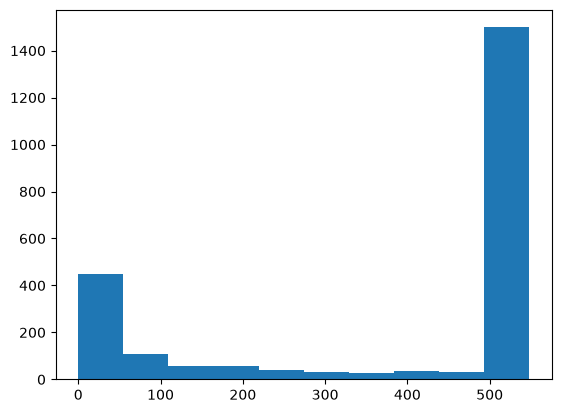

In [9]:
#plot distribution of data (TBC)
plt.hist(df['surv18'])


In [10]:
target = 'surv18' # for regression
# target = 'surv18_class' # for classification

#define predictor columns
clean_df = df[[target]+variable_type['metadata_var']+variable_type['randomisation_var']+['itt_treat']]
#drop columns 
clean_df.drop(columns=['randhosp_id', 'randpat_id', 'trialphase', 'agecat', 'ageimp', 'age_true', 'UKextra',
                     #   'gotbolus', 'infus_start', 'infus_halt', 'totdose', 'nostartcode', 'treatment', 'haltcode',
                       'randvioltype'], inplace=True)
clean_df

,surv18,pretrialexp,country,phase,gender,weight,glucose,age,randyear,randmonth,...,sbpstart,sbp30min,sbp60min,sbp24h,dbpstart,dbp30min,dbp60min,dbp24h,treatdelay,itt_treat
0,158.0,2.0,UK,2.0,1.0,55.0,5.0,81.0,2006.0,7.0,...,178.0,165.0,180.0,155.0,70.0,65.0,70.0,65.0,3.716667,0.0
1,548.0,1.0,SWEDEN,2.0,1.0,68.0,6.0,92.0,2011.0,6.0,...,190.0,175.0,170.0,160.0,85.0,115.0,90.0,100.0,2.166667,1.0
2,548.0,1.0,POLAND,2.0,1.0,70.0,6.0,75.0,2008.0,6.0,...,130.0,160.0,160.0,140.0,85.0,80.0,90.0,78.0,5.383333,1.0
3,548.0,2.0,UK,2.0,1.0,66.0,5.0,60.0,2007.0,4.0,...,123.0,99.0,108.0,120.0,69.0,69.0,70.0,74.0,4.666667,0.0
7,548.0,2.0,AUSTRALIA,2.0,2.0,80.0,8.0,67.0,2009.0,5.0,...,174.0,179.0,191.0,175.0,73.0,95.0,97.0,95.0,5.966667,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3027,548.0,1.0,SWEDEN,2.0,2.0,100.0,14.0,70.0,2008.0,7.0,...,176.0,151.0,149.0,155.0,87.0,108.0,74.0,95.0,5.933333,0.0
3028,6.0,1.0,UK,1.0,1.0,60.0,NaN,85.0,2001.0,10.0,...,165.0,165.0,115.0,145.0,85.0,80.0,55.0,65.0,4.316667,1.0
3030,548.0,2.0,UK,2.0,1.0,55.0,7.0,83.0,2006.0,12.0,...,174.0,164.0,193.0,184.0,86.0,85.0,98.0,93.0,5.133333,1.0
3032,548.0,1.0,UK,2.0,1.0,70.0,16.0,84.0,2009.0,9.0,...,144.0,130.0,105.0,122.0,105.0,80.0,75.0,75.0,2.500000,0.0


In [11]:
clean_df.isna().sum()

surv18                   0
pretrialexp              0
country                  0
phase                    0
gender                   0
weight                   0
glucose                282
age                      0
randyear                 0
randmonth                0
randhour                 0
randmin                  0
randdelay                0
livealone_rand           0
indepinadl_rand          0
nobleed_rand             0
infarct                  0
antiplat_rand            0
atrialfib_rand           0
sbprand                  0
dbprand                 19
gcs_eye_rand             0
gcs_motor_rand           0
gcs_verbal_rand          0
gcs_score_rand           0
nihss                    0
liftarms_rand            0
ablewalk_rand            0
weakface_rand            0
weakarm_rand             0
weakleg_rand             0
dysphasia_rand           0
hemianopia_rand          0
visuospat_rand           0
brainstemsigns_rand      0
otherdeficit_rand        0
stroketype               0
p

In [12]:
clean_df.dropna(how="any", inplace=True)

In [13]:
clean_df.dtypes

surv18                 float64
pretrialexp            float64
country                    str
phase                  float64
gender                 float64
weight                 float64
glucose                float64
age                    float64
randyear               float64
randmonth              float64
randhour               float64
randmin                float64
randdelay              float64
livealone_rand         float64
indepinadl_rand        float64
nobleed_rand           float64
infarct                float64
antiplat_rand          float64
atrialfib_rand         float64
sbprand                float64
dbprand                float64
gcs_eye_rand           float64
gcs_motor_rand         float64
gcs_verbal_rand        float64
gcs_score_rand         float64
nihss                  float64
liftarms_rand          float64
ablewalk_rand          float64
weakface_rand          float64
weakarm_rand           float64
weakleg_rand           float64
dysphasia_rand         float64
hemianop

In [14]:
from sklearn.preprocessing import OneHotEncoder

#OHE string columns
encoder = OneHotEncoder(sparse_output=False)
encoded = encoder.fit_transform(clean_df[['country']])
encoded_df = pd.DataFrame(encoded,columns=encoder.get_feature_names_out(['country']),index=clean_df.index)

In [15]:
clean_df = clean_df.join(encoded_df).drop(['country'], axis=1)

In [16]:
clean_df

,surv18,pretrialexp,phase,gender,weight,glucose,age,randyear,randmonth,randhour,...,treatdelay,itt_treat,country_AUSTRALIA,country_BELGIUM,country_ITALY,country_NORWAY,country_OTHER,country_POLAND,country_SWEDEN,country_UK
0,158.0,2.0,2.0,1.0,55.0,5.0,81.0,2006.0,7.0,11.0,...,3.716667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,548.0,1.0,2.0,1.0,68.0,6.0,92.0,2011.0,6.0,16.0,...,2.166667,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,548.0,1.0,2.0,1.0,70.0,6.0,75.0,2008.0,6.0,14.0,...,5.383333,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,548.0,2.0,2.0,1.0,66.0,5.0,60.0,2007.0,4.0,14.0,...,4.666667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
7,548.0,2.0,2.0,2.0,80.0,8.0,67.0,2009.0,5.0,14.0,...,5.966667,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3026,5.0,2.0,2.0,1.0,48.0,7.0,87.0,2009.0,3.0,0.0,...,4.383333,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3027,548.0,1.0,2.0,2.0,100.0,14.0,70.0,2008.0,7.0,14.0,...,5.933333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3030,548.0,2.0,2.0,1.0,55.0,7.0,83.0,2006.0,12.0,13.0,...,5.133333,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3032,548.0,1.0,2.0,1.0,70.0,16.0,84.0,2009.0,9.0,12.0,...,2.500000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(clean_df.drop(target, axis=1), clean_df[target], 
                                                    test_size=0.2, random_state=42)

In [18]:
X_train

,pretrialexp,phase,gender,weight,glucose,age,randyear,randmonth,randhour,randmin,...,treatdelay,itt_treat,country_AUSTRALIA,country_BELGIUM,country_ITALY,country_NORWAY,country_OTHER,country_POLAND,country_SWEDEN,country_UK
1973,2.0,2.0,1.0,80.0,10.0,81.0,2009.0,1.0,11.0,0.0,...,1.983333,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2820,1.0,2.0,1.0,61.0,8.0,81.0,2008.0,2.0,23.0,30.0,...,3.083333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
938,2.0,2.0,1.0,80.0,10.0,76.0,2007.0,10.0,17.0,20.0,...,5.966667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1218,1.0,2.0,1.0,90.0,8.0,60.0,2005.0,6.0,19.0,43.0,...,4.666667,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1508,2.0,2.0,2.0,58.0,5.0,91.0,2007.0,8.0,12.0,30.0,...,3.750000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1890,2.0,2.0,2.0,75.0,11.0,71.0,2008.0,4.0,12.0,8.0,...,3.933333,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2178,2.0,2.0,1.0,43.0,5.0,91.0,2010.0,6.0,21.0,55.0,...,5.000000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1443,2.0,2.0,2.0,85.0,8.0,68.0,2007.0,8.0,13.0,0.0,...,6.083333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2422,1.0,2.0,2.0,60.0,6.0,68.0,2006.0,1.0,3.0,50.0,...,6.133333,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [19]:
from supervised_ml import RunRegressionModels

test_run = RunRegressionModels(X_train, y_train, X_test, y_test)
test_run.run_linear_regression()
test_run.run_lasso_regression()
test_run.run_lassocv_regression()
test_run.run_ridge_regression()
test_run.run_ridgecv_regression()
test_run.run_decisiontree_regression()
test_run.run_svm_regression()
test_run.run_randomforest_regression()
test_run.run_gradboost_regression()

In [20]:
test_run.train_df

,pretrialexp,phase,gender,weight,glucose,age,randyear,randmonth,randhour,randmin,...,country_UK,actual,linear_reg,lasso_reg,lassocv_reg,ridge_reg,ridgecv_reg,decisiontree_reg,svm_reg,randomforest_reg
1973,2.0,2.0,1.0,80.0,10.0,81.0,2009.0,1.0,11.0,0.0,...,1.0,183.0,396.058700,396.271587,388.222168,396.153463,392.021692,183.0,547.897629,302.299117
2820,1.0,2.0,1.0,61.0,8.0,81.0,2008.0,2.0,23.0,30.0,...,0.0,548.0,471.388192,478.008021,466.936901,472.518786,473.131620,548.0,547.900648,490.194960
938,2.0,2.0,1.0,80.0,10.0,76.0,2007.0,10.0,17.0,20.0,...,1.0,548.0,508.806243,508.618278,475.446128,509.135312,498.027282,548.0,547.901416,547.385572
1218,1.0,2.0,1.0,90.0,8.0,60.0,2005.0,6.0,19.0,43.0,...,0.0,548.0,486.047531,487.560596,497.140760,486.474220,500.478666,548.0,547.904451,494.210951
1508,2.0,2.0,2.0,58.0,5.0,91.0,2007.0,8.0,12.0,30.0,...,1.0,129.0,227.304170,226.904644,239.314599,227.168639,225.296185,129.0,547.887290,123.275428
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1890,2.0,2.0,2.0,75.0,11.0,71.0,2008.0,4.0,12.0,8.0,...,1.0,392.0,251.818402,251.085404,301.485267,251.422881,253.471036,392.0,547.892095,238.228400
2178,2.0,2.0,1.0,43.0,5.0,91.0,2010.0,6.0,21.0,55.0,...,0.0,548.0,431.703860,431.273774,430.789497,432.215154,435.398130,548.0,547.898400,429.112528
1443,2.0,2.0,2.0,85.0,8.0,68.0,2007.0,8.0,13.0,0.0,...,1.0,548.0,373.960231,374.675385,392.292487,374.061022,379.446935,548.0,547.898086,460.956786
2422,1.0,2.0,2.0,60.0,6.0,68.0,2006.0,1.0,3.0,50.0,...,0.0,548.0,493.377469,493.326383,510.849326,493.105791,498.043106,548.0,547.904605,531.033872


In [21]:
test_run.train_df

,pretrialexp,phase,gender,weight,glucose,age,randyear,randmonth,randhour,randmin,...,country_UK,actual,linear_reg,lasso_reg,lassocv_reg,ridge_reg,ridgecv_reg,decisiontree_reg,svm_reg,randomforest_reg
1973,2.0,2.0,1.0,80.0,10.0,81.0,2009.0,1.0,11.0,0.0,...,1.0,183.0,396.058700,396.271587,388.222168,396.153463,392.021692,183.0,547.897629,302.299117
2820,1.0,2.0,1.0,61.0,8.0,81.0,2008.0,2.0,23.0,30.0,...,0.0,548.0,471.388192,478.008021,466.936901,472.518786,473.131620,548.0,547.900648,490.194960
938,2.0,2.0,1.0,80.0,10.0,76.0,2007.0,10.0,17.0,20.0,...,1.0,548.0,508.806243,508.618278,475.446128,509.135312,498.027282,548.0,547.901416,547.385572
1218,1.0,2.0,1.0,90.0,8.0,60.0,2005.0,6.0,19.0,43.0,...,0.0,548.0,486.047531,487.560596,497.140760,486.474220,500.478666,548.0,547.904451,494.210951
1508,2.0,2.0,2.0,58.0,5.0,91.0,2007.0,8.0,12.0,30.0,...,1.0,129.0,227.304170,226.904644,239.314599,227.168639,225.296185,129.0,547.887290,123.275428
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1890,2.0,2.0,2.0,75.0,11.0,71.0,2008.0,4.0,12.0,8.0,...,1.0,392.0,251.818402,251.085404,301.485267,251.422881,253.471036,392.0,547.892095,238.228400
2178,2.0,2.0,1.0,43.0,5.0,91.0,2010.0,6.0,21.0,55.0,...,0.0,548.0,431.703860,431.273774,430.789497,432.215154,435.398130,548.0,547.898400,429.112528
1443,2.0,2.0,2.0,85.0,8.0,68.0,2007.0,8.0,13.0,0.0,...,1.0,548.0,373.960231,374.675385,392.292487,374.061022,379.446935,548.0,547.898086,460.956786
2422,1.0,2.0,2.0,60.0,6.0,68.0,2006.0,1.0,3.0,50.0,...,0.0,548.0,493.377469,493.326383,510.849326,493.105791,498.043106,548.0,547.904605,531.033872


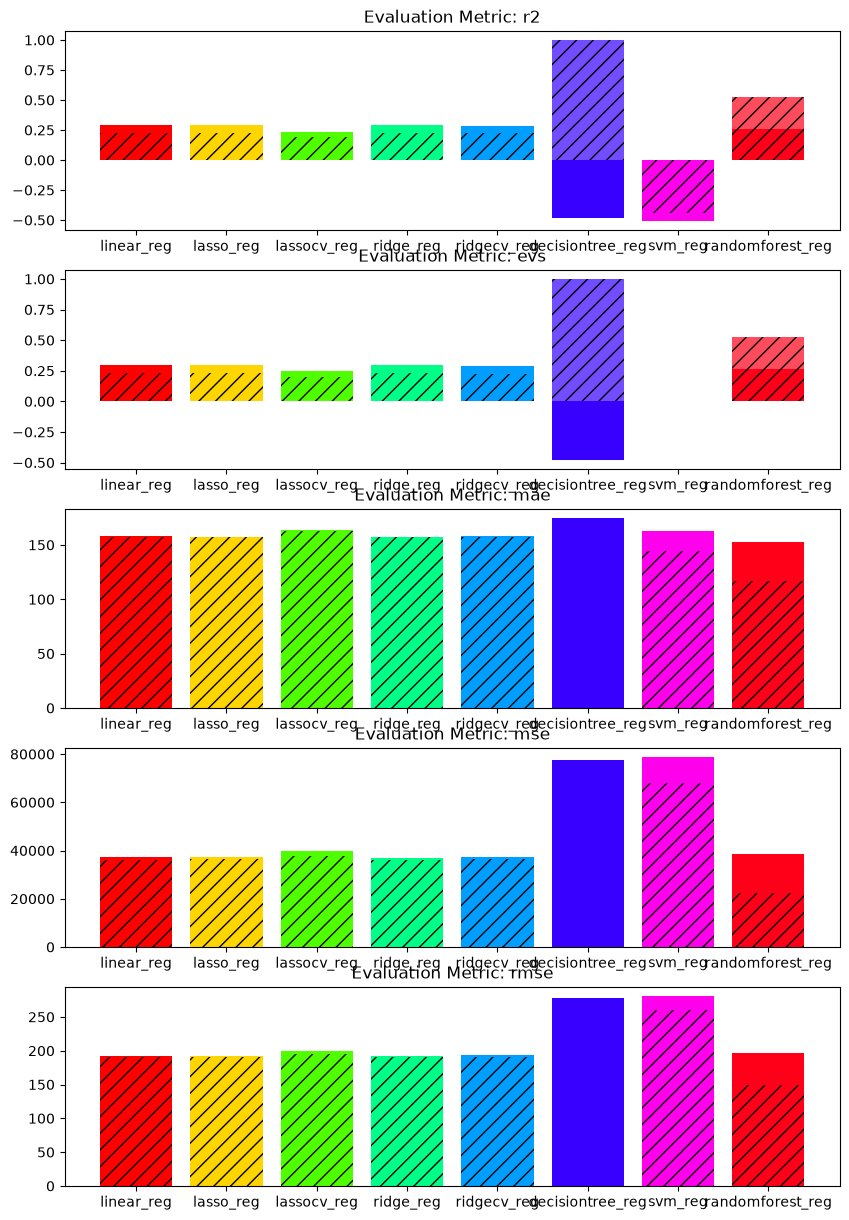

In [26]:
colors = plt.cm.hsv(np.linspace(0, 1, len(test_run.test_metrics_all.keys())))

fig = plt.figure(figsize=(10, 15))
gs = fig.add_gridspec(5, 1)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[2, 0])
ax4 = fig.add_subplot(gs[3, 0])
ax5 = fig.add_subplot(gs[4, 0])  # Spans both columns

for ax, metric in zip([ax1, ax2, ax3, ax4, ax5], ['r2', 'evs', 'mae', 'mse', 'rmse']):
    for key, color in zip(test_run.test_metrics_all.keys(), colors):
        ax.bar(key, test_run.test_metrics_all[key][metric], color=color)
        ax.bar(key, test_run.train_metrics_all[key][metric], hatch="//", color=color, alpha=0.7)
        ax.set_title(f"Evaluation Metric: {metric}")

# plt.tight_layout()
# plt.show()

Note to self: 
* regression models in general are not able to capture relationship between variables and target well with low r2 and relatively high mae, considering max value of target is in the 500s
* models operating under the assumption of linearity perform similarly to each other, comparing train and test metrics dont seem to indicate overfitting, except for decision tree
* small improvement seen on random forest that doesnt assume linearity; non-linear models to explore further

To check:
* why is svm particularly bad?
* how to reduce overfitting on decision tree?
* uneven distribution of target, 
* does classification of target improve results?
